In [2]:
import numpy as np
import random
import pandas as pd
import time
import matplotlib.pyplot as plt

## Funções

In [2]:
# seed= 42
# rng = np.random.default_rng(seed)
def cria_individuos (n, limites, rng):
    """ Os valores especificados no pdf. n=2, 5 e 10 
    limites=[-5,5] 
    """
    individuo = rng.uniform(limites[0], limites[1], n) # A distribuição uniforme dá a mesma probabilidade de sortear qualquer valor entre -5 e 5
    return individuo

# cria_individuos(3 , [-5,5])

In [3]:
def criar_populacao(tamanho, n, limites, rng): #— gera N indivíduos.
    populacao = []
    for i in range (tamanho):
        populacao.append(cria_individuos(n, limites, rng))
    populacao = np.array(populacao)
    return populacao

In [4]:
# 1: Função Esférica 
def sphere (x: np. ndarray ) -> float :
    return np. sum(x **2) # Potência de 2

# 2: Função Rastrigin 
def rastrigin (x: np. ndarray ) -> float :
    n = len(x) 
    return 10 * n + np.sum(x**2 - 10 * np.cos (2 * np.pi * x)) 

# 3: Função Rosenbrock 
def rosenbrock (x: np. ndarray ) -> float : 
    return np. sum (100*( x [1:] - x [: -1]**2) **2 + (x[: -1] -1) **2)

def avaliar_populacao(funcao_objetivo, nfe_atual, populacao): # o nfe_atual deverá ser revisado!
    fitness = np.apply_along_axis(funcao_objetivo,  axis= 1, arr=populacao)
    nfe_atualizado = nfe_atual + len(populacao)
    return fitness , nfe_atualizado

In [5]:
def torneio(fitness, populacao, k, rng): # O torneio busca por valores mais proximos de zero.
    """ K: é número individuos
    Retorna um endividuo (o vencedor da rodada).
    """
    posicao = np.arange(len(fitness))
    # rng =np.random.default_rng()
    sorteados = rng.choice(posicao, k, replace=False)
    disputa = fitness[sorteados]
    vencedor_indice = np.argmin(disputa)
    p_vencedor = sorteados[vencedor_indice]
    return populacao[p_vencedor]

In [6]:
def crossover(pai1, pai2, pc, rng):
    r = rng.uniform(0,1)   
    if pc >= r:
        a = rng.uniform(0,1)
        filho1 = (a * pai1) + ((1-a) * pai2)
        filho2 = ((1-a)* pai1) + (a * pai2)
        return filho1, filho2
    else: 
        return pai1 , pai2

In [7]:
def mutacao(individuo, pm, sigma, limites,rng):
    """ individuo = filho;
    pm = probabilidade de mutação;
    sigma = é o valor da mutação
     limites = [-5,5]
    """

    r = rng.uniform(0,1)   
    if pm >= r: 
        individuo = rng.normal(individuo, sigma, len(individuo))
        individuo = np.clip(individuo, limites[0],limites[1])
        return individuo
    else:
        return individuo

In [15]:
def executar_experimentos(funcoes, dimensoes, seeds, config_base, nfe_max):
    """
    funcoes: lista de tuplas (nome_str, funcao) -> ex: [("sphere", sphere), ...]
    dimensoes: lista de n -> ex: [2, 5, 10]
    seeds: lista de seeds -> ex: list(range(10))
    config_base: dict com tamanho, pc, pm, k, sigma, limites (mesma config p/ todas)
    """
    resultados = []        # uma linha por execução (função x dimensão x seed)
    historicos = {}        # guarda o histórico de convergência de cada execução

    for nome_fo, fo in funcoes:
        for n in dimensoes:
            for seed in seeds:

                inicio = time.perf_counter()
                teste = ag (seed, tamanho, n, limites,fo, nfe_i,pc, pm, k, sigma, nfe_max ) 
       
                fim = time.perf_counter()
                tempo_execucao = fim - inicio

                # TODO: guardar o histórico num dicionário, com uma chave que identifique
                #       essa execução única (ex: (nome_fo, n, seed))
                historicos[(nome_fo, n, seed)] = None  # substituir por 'historico'

                resultados.append({
                    "funcao": nome_fo,
                    "dimensao": n,
                    "seed": seed,
                    "melhor_fitness": resultados[3],
                    "nfe_final": resultados[4],
                    "tempo_execucao": tempo_execucao,
                })

    df_resultados = pd.DataFrame(resultados)
    return df_resultados, historicos

In [47]:
# 1. Convergência de uma única execução (uma seed, uma função, uma dimensão)
def plotar_convergencia_execucao(historico, tamanho, titulo="Convergência"):
    """historico: lista retornada por ag() (teste[2])"""
    nfe_eixo = [(i + 2) * tamanho for i in range(len(historico))]  # 1ª avaliação (pop inicial) não entra no histórico
    plt.figure(figsize=(7, 4))
    plt.plot(nfe_eixo, historico)
    plt.xlabel("NFE (avaliações da função objetivo)")
    plt.ylabel("Melhor fitness")
    plt.yscale("log")  # fitness costuma variar em ordens de grandeza
    plt.title(titulo)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# 2. Convergência média (± desvio padrão) sobre as 10 seeds, para uma função/dimensão
def plotar_convergencia_media(historicos, nome_funcao, n, seeds, tamanho, titulo=None):
    curvas = [historicos[(nome_funcao, n, seed)] for seed in seeds]
    curvas = np.array(curvas)  # shape (n_seeds, n_geracoes) -> funciona pois todas têm o mesmo nº de gerações

    media = curvas.mean(axis=0)
    desvio = curvas.std(axis=0)
    nfe_eixo = [(i + 2) * tamanho for i in range(curvas.shape[1])]

    plt.figure(figsize=(7, 4))
    plt.plot(nfe_eixo, media, label="Média")
    plt.fill_between(nfe_eixo, media - desvio, media + desvio, alpha=0.3, label="± 1 desvio padrão")
    plt.xlabel("NFE")
    plt.ylabel("Melhor fitness")
    plt.yscale("log")
    plt.title(titulo or f"{nome_funcao} (n={n}) — média de {len(seeds)} execuções")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# 3. Comparar as curvas médias das 3 funções, para uma mesma dimensão
def plotar_comparacao_funcoes(historicos, nomes_funcoes, n, seeds, tamanho):
    plt.figure(figsize=(7, 4))
    for nome_funcao in nomes_funcoes:
        curvas = np.array([historicos[(nome_funcao, n, seed)] for seed in seeds])
        media = curvas.mean(axis=0)
        nfe_eixo = [(i + 2) * tamanho for i in range(curvas.shape[1])]
        plt.plot(nfe_eixo, media, label=nome_funcao)

    plt.xlabel("NFE")
    plt.ylabel("Melhor fitness (média)")
    plt.yscale("log")
    plt.title(f"Comparação entre funções (n={n})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# 4. Boxplot dos resultados finais (dispersão entre as 10 seeds), por função e dimensão
def plotar_boxplot_resultados(df_resultados, n):
    subset = df_resultados[df_resultados["dimensao"] == n]
    dados = [subset[subset["funcao"] == f]["melhor_fitness"].values for f in subset["funcao"].unique()]

    plt.figure(figsize=(7, 4))
    plt.boxplot(dados, tick_labels=subset["funcao"].unique())
    plt.ylabel("Melhor fitness final")
    plt.yscale("log")
    plt.title(f"Dispersão dos resultados finais (n={n})")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# 5. Tabela de estatísticas exigida pela Seção 6 do enunciado
def calcular_estatisticas(df_resultados):
    return df_resultados.groupby(["funcao", "dimensao"]).agg(
        melhor_solucao=("melhor_fitness", "min"),
        media=("melhor_fitness", "mean"),
        desvio_padrao=("melhor_fitness", "std"),
        nfe_medio=("nfe_final", "mean"),
        tempo_medio=("tempo_execucao", "mean"),
    ).reset_index()

In [8]:
# def confere_pais(pai1, pai2):
#     aprovado = True
#     while aprovado == True:
#         print('Comessou')
#         if np.array_equal(pai1, pai2) != True:
#             aprovado = False
#             return pai1, pai2
#         else:
#             pai2 = torneio(fit, p1, 2)
            

## Agoritmo genetico

In [9]:
def ag(seed, tamanho, n, limites, 
       fo, nfe_i,pc, pm,
       k, sigma, nfe_max        
       ): # Passar todos os parametros aqui
    # print(f'NFE: {nfe_i} \nInicio do cliclo.')
    rng = np.random.default_rng(seed)
    historico_convergencia = []
    populacao =criar_populacao(tamanho, n, limites, rng) #tamanho, n, limites, rng

    avaliacao = avaliar_populacao(fo,nfe_i, populacao)
    fitness = avaliacao[0]
    nfe = avaliacao[1]
    
    while (nfe < nfe_max):
        i = 0
        nova_populacao = []
        while i < tamanho:
            pai1 = torneio(fitness,populacao, k, rng)
            pai2 = torneio(fitness,populacao, k, rng)

            reproducao = crossover(pai1, pai2, pc, rng)
            filho1 = reproducao[0]
            filho2 =  reproducao[1]

            filho1 = mutacao(filho1, pm, sigma, limites, rng)
            filho2 = mutacao(filho2, pm, sigma, limites, rng)

            nova_populacao.append(filho1)
            nova_populacao.append(filho2)

                      
            i = len(nova_populacao) 

        nova_populacao = np.array(nova_populacao)[:tamanho]  
        avaliacao = avaliar_populacao(fo,nfe, nova_populacao)      
        fitness = avaliacao[0]
        historico_convergencia.append(fitness.min())
        nfe = avaliacao[1]
        populacao = nova_populacao

    # print(f'NFE: {nfe} \nFim do cliclo.')
    
    posicao = np.argmin(fitness)
    melhor_solucao = populacao[posicao]

    melhor_fitness = fitness[posicao]
    
    return populacao , melhor_solucao, historico_convergencia, melhor_fitness, nfe
    


## Testes

In [10]:
# Parametros

seed = 42 # é o rgn

# Criar a população:
tamanho = 100 # tamanho da população
n = 2 # dimensão do problema: começa com: 2, 5 e 10;
limites = [-5,5] # (domínio, ex: [-5,5])


fo = sphere # rastrigin ou rosenbrock)
nfe_i = 0
pc = 0.33 # (prob. crossover)
pm = 0.33 # (prob. mutação)
k = 2 # tamanho do torneio: é o numero de individuos chamdos em uma rodada.
sigma = 0.5 # (desvio padrão da mutação)

nfe_max = 20000 # (critério de parada)


##### Testes

In [11]:
teste = ag(seed, tamanho, n, limites, 
       fo, nfe_i,pc, pm,
       k, sigma, nfe_max        
       )

In [12]:
# populacao
teste[0]

array([[-2.84206746e-02, -1.16328087e-02],
       [ 1.31840372e-03, -9.70208219e-04],
       [ 1.64311347e-02, -5.95747003e-03],
       [-2.84206746e-02, -1.16328087e-02],
       [ 4.97293282e-03,  2.90197619e-02],
       [ 2.11200005e-02,  4.63367076e-03],
       [ 1.79698611e-01, -9.51364410e-02],
       [ 6.50401326e-02, -3.44941408e-02],
       [-7.00235468e-02,  6.01654337e-02],
       [ 4.77428705e-02, -3.28039897e-01],
       [ 3.64300917e-04, -2.32505553e-04],
       [ 6.87744081e-04, -4.34704386e-04],
       [-2.84206746e-02, -1.16328087e-02],
       [ 8.78948886e-02, -3.49134668e-02],
       [-4.47813924e-01,  6.14867268e-01],
       [-2.33933988e-02, -5.51272457e-03],
       [-4.59119957e-01, -6.03991295e-01],
       [ 9.34783023e-04, -5.89139513e-04],
       [ 6.95532712e-01, -1.92723728e-03],
       [-1.65657790e-03,  1.61541748e-03],
       [ 1.56833549e-02,  7.84176253e-03],
       [ 7.89970037e-01,  6.28632102e-01],
       [ 1.17261974e-04, -7.80704262e-05],
       [ 4.

In [13]:
# melhor solução
teste[1]

array([ 1.17261974e-04, -7.80704262e-05])

In [14]:
# historico_convergencia
teste[2]

[np.float64(0.026436008995089022),
 np.float64(0.10176742611996015),
 np.float64(0.01939104244592059),
 np.float64(0.005508624367160672),
 np.float64(0.002068230441427973),
 np.float64(0.0010541507787383937),
 np.float64(0.0012642206395862335),
 np.float64(0.0012642206395862335),
 np.float64(0.0012642206395862335),
 np.float64(0.001661546882210172),
 np.float64(0.0011673037921589883),
 np.float64(0.0006327592522686338),
 np.float64(0.0005277278041937821),
 np.float64(0.0004458505690166146),
 np.float64(0.00024184805717669992),
 np.float64(0.00037854036579571497),
 np.float64(0.00037854036579571497),
 np.float64(0.00017689449593241325),
 np.float64(0.00017689449593241325),
 np.float64(0.00017689449593241325),
 np.float64(6.136433682250946e-05),
 np.float64(6.136433682250946e-05),
 np.float64(6.136433682250946e-05),
 np.float64(8.104732703372383e-06),
 np.float64(5.652878380084593e-06),
 np.float64(8.104732703372383e-06),
 np.float64(9.335241175101133e-06),
 np.float64(9.335241175101133e

# Execuções

In [16]:
# Lista de tuplas (nome, função) — corrige o Erro 1
funcoes = [("sphere", sphere), ("rastrigin", rastrigin), ("rosenbrock", rosenbrock)]
dimensoes = [2, 5, 10]
seeds = [42, 89, 13, 21, 12, 90, 14, 10, 63, 24]
nfe_max = 20000
config_base = {"tamanho": tamanho, "pc": pc, "pm": pm, "k": k, "sigma": sigma, "limites": limites}


# Execuções

In [18]:
final = executar_experimentos(funcoes, dimensoes, seeds, config_base, nfe_max)

In [19]:
df = final[0]

In [20]:
(df['melhor_fitness'].min())*1000000000

np.float64(0.1597335816968324)

In [21]:
df.head()

,funcao,dimensao,seed,melhor_fitness,nfe_final,tempo_execucao
0,sphere,2,42,1.984536e-08,20000,0.231835
1,sphere,2,89,3.066382e-09,20000,0.204560
2,sphere,2,13,1.946598e-07,20000,0.205147
3,sphere,2,21,5.150507e-09,20000,0.205404
4,sphere,2,12,2.803287e-06,20000,0.204405


In [22]:
# melhor fitness
df.loc[df['melhor_fitness'] == df['melhor_fitness'].min()]

,funcao,dimensao,seed,melhor_fitness,nfe_final,tempo_execucao
5,sphere,2,90,1.597336e-10,20000,0.203941


In [23]:
df['melhor_fitness'].describe()

count    9.000000e+01
mean     3.257663e+00
std      6.547703e+00
min      1.597336e-10
25%      4.271920e-05
50%      3.345307e-03
75%      3.954498e+00
max      4.924365e+01
Name: melhor_fitness, dtype: float64

In [24]:
print(f'Desvio padrão melhores Fitness: \n>>> {df['melhor_fitness'].std():.4f}')
print('\n*****************************\n')
print(f'Desvio padrão do tempo de execução: \n>>> {df['tempo_execucao'].std():.4f}')


Desvio padrão melhores Fitness: 
>>> 6.5477

*****************************

Desvio padrão do tempo de execução: 
>>> 0.0200


# Análise Gráfica

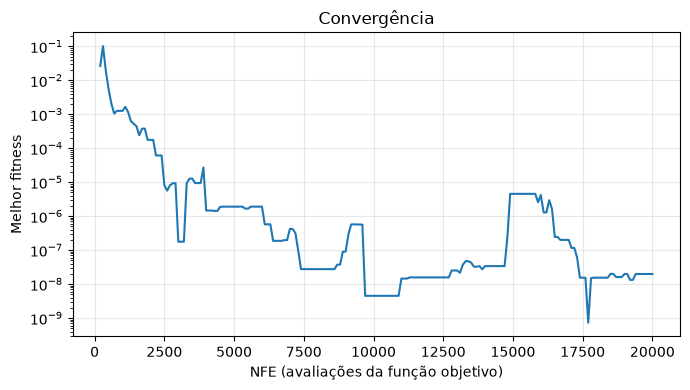

In [26]:
# 1. Convergência de uma única execução (uma seed, uma função, uma dimensão)
historico = final[1][("sphere", n, seeds[0])]
plotar_convergencia_execucao(historico, tamanho, titulo="Convergência")

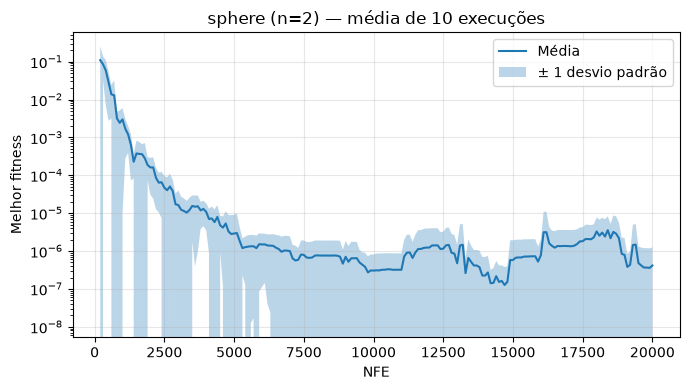

In [44]:
# 2. Convergência média (± desvio padrão) sobre as 10 seeds, para uma função/dimensão
plotar_convergencia_media(final[1], "sphere", 2, seeds, tamanho, titulo=None)

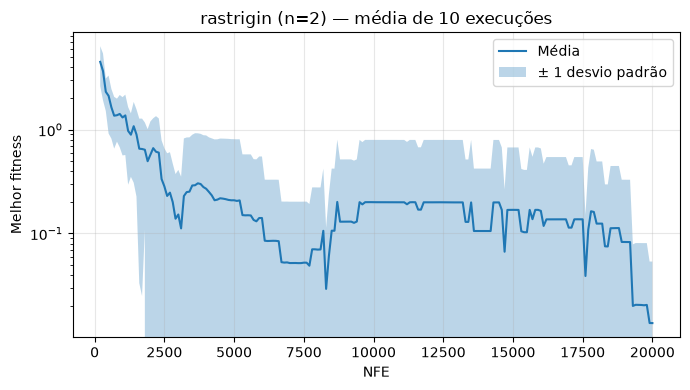

In [37]:
# 2. Convergência média (± desvio padrão) sobre as 10 seeds, para uma função/dimensão
plotar_convergencia_media(final[1], "rastrigin", 2, seeds, tamanho, titulo=None)

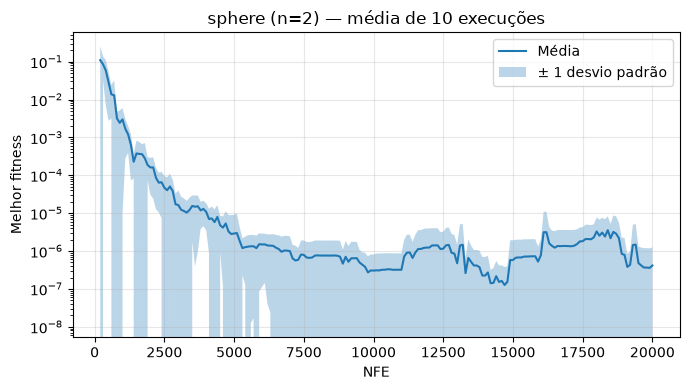

In [41]:
# 2. Convergência média (± desvio padrão) sobre as 10 seeds, para uma função/dimensão
plotar_convergencia_media(final[1], "sphere", 2, seeds, tamanho, titulo=None)

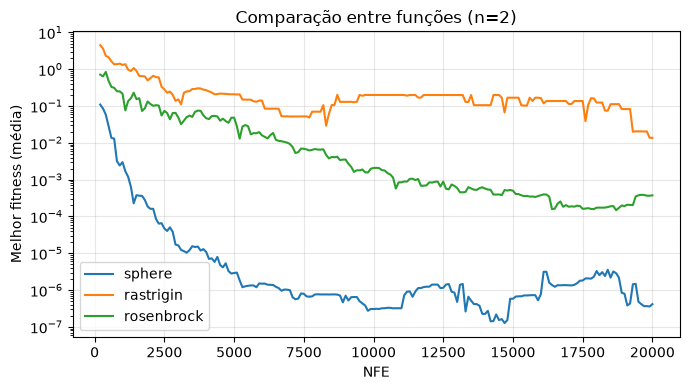

In [30]:
# 3. Comparar as curvas médias das 3 funções, para uma mesma dimensão
historicos = final[1]
nomes_funcoes = ["sphere", "rastrigin", "rosenbrock"]
plotar_comparacao_funcoes(historicos, nomes_funcoes, n, seeds, tamanho)

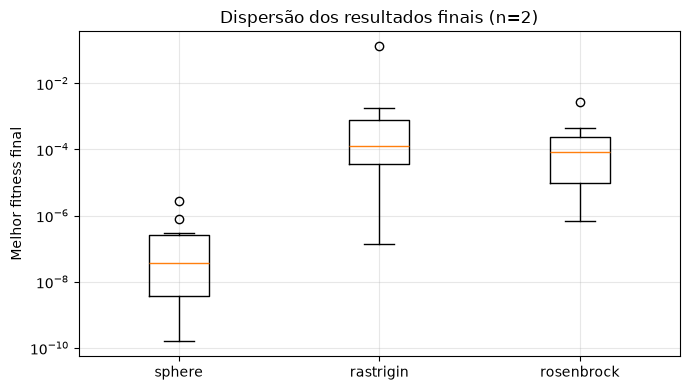

In [31]:
# 4. Boxplot dos resultados finais (dispersão entre as 10 seeds), por função e dimensão
plotar_boxplot_resultados(df, n)

In [45]:
# 5. Tabela de estatísticas exigida pela Seção 6 do enunciado
calcular_estatisticas(df)

,funcao,dimensao,melhor_solucao,media,desvio_padrao,nfe_medio,tempo_medio
0,rastrigin,2,1.368802e-07,1.370737e-02,4.213931e-02,20000.0,0.236804
1,rastrigin,5,1.016923e-01,2.239183e+00,1.481342e+00,20000.0,0.236857
2,rastrigin,10,4.474195e+00,1.039724e+01,4.981656e+00,20000.0,0.238935
3,rosenbrock,2,7.065358e-07,3.750274e-04,8.172173e-04,20000.0,0.253022
4,rosenbrock,5,1.711688e+00,2.848713e+00,8.805456e-01,20000.0,0.253746
5,rosenbrock,10,8.570858e+00,1.381565e+01,1.247051e+01,20000.0,0.254248
6,sphere,2,1.597336e-10,4.142782e-07,8.735723e-07,20000.0,0.207405
7,sphere,5,8.424441e-06,5.926261e-05,5.796426e-05,20000.0,0.205174
8,sphere,10,1.335721e-03,4.042959e-03,3.469495e-03,20000.0,0.206189
